# 02 · التنبؤ بمتوسط درجة الطالب **الشهر الجاي** (Linear Regression + موديلات للمقارنة)

## إيه اللي اتغير عن النسخة الأولى ولماذا؟
النسخة الأولى طلّعت **R² ≈ 0.95**، والرقم ده كان **تسريب (leakage)** مش جودة حقيقية:

| الحالة | MAE | R² |
|---|---|---|
| بـ `notes` (عمود نصي بيقول "ممتاز جدا / ضعيف…" يعني نفس الإجابة) | 2.84 | 0.954 |
| من غير `notes` و`attendance_notes` | 7.30 | 0.697 |
| baseline: متوسط كل درجات الطالب السابقة | 7.80 | 0.647 |

وكمان أعمدة التواريخ (`start_date`, `join_date`) كانت بتدخل كأرقام ضخمة وبتبوّظ الـ Linear.

**التصليحات:**
1. **قايمة features صريحة (allowlist)** بدل الاختيار التلقائي. مفيش عمود بيدخل غير لو إحنا اخترناه. وفي `assert` بيوقف النوت بوك لو دخل اسم فيه `note` أو `date`.
2. **الهدف اتغير:** `متوسط درجات الطالب في الشهر ده`، وكل الـ features من **الشهور اللي قبله بس**. ده كمان السؤال المفيد للمدرس: "الطالب ده الشهر الجاي هيبقى كام؟".
3. **baselines صريحة:** (آخر شهر) و(متوسط كل الشهور السابقة). أي موديل لازم يكسبهم، وده اللي بيثبت إنه بيضيف قيمة.
4. التقسيم بالطالب (train/test من `01_cleaning`)، والـ CV بـ `GroupKFold` على `student_id`.

In [1]:
%run -i ./01_cleaning.ipynb

{'Students': (1002, 12), 'Groups': (41, 8), 'Sessions': (1442, 6), 'Records': (34834, 16), 'Payments': (8713, 9)}
Students  (1002, 12)
Groups    (41, 8)
Sessions  (1442, 6)
Records   (34834, 16)
Payments  (8713, 9)
القيم الناقصة في كل جدول (الأعمدة اللي فيها فاضي بس):

Students: {'name': 1, 'phone': 1, 'parent_phone': 1, 'group_id': 1, 'gender': 1, 'grade': 1, 'school_type': 1, 'area': 1, 'join_date': 1, 'status': 1, 'leave_date': 972}

Groups: {'group_name': 1, 'day': 1, 'time': 1, 'grade': 1, 'track': 1, 'monthly_fee': 1, 'start_date': 1}

Sessions: {'group_id': 1, 'date': 1, 'session_number': 1, 'month': 1, 'session_type': 1}

Records: {'student_id': 43, 'session_id': 43, 'date': 43, 'attendance': 43, 'homework': 43, 'exam_score': 2744, 'max_exam_score': 2745, 'percentage': 2744, 'notes': 2721, 'student_session_number': 43, 'group_month': 43, 'group_session': 43, 'student_month': 43, 'student_session': 44, 'attendance_notes': 31883}

Payments: {'student_id': 10, 'month_label': 10, '

In [12]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
SEED = 42
print('train students:', len(train_ids), '| test students:', len(test_ids))

train students: 800 | test students: 200


## 1) جدول (طالب × شهر)

* صف لكل طالب في كل شهر. الـ target = متوسط `percentage` في الشهر ده.
* كل feature متحسوب من الشهور **اللي قبل** الشهر ده (`shift`)، فالشهر ما بيشوفش نفسه.
* الـ features الثابتة **قايمة صريحة** (`STATIC_CAT`): ممنوع أي نوتس أو تواريخ.

In [14]:
HW_MAP  = {'ممتاز': 5, 'جيد جدا': 4, 'جيد': 3, 'مقبول': 2, 'ضعيف': 1, 'لم يسلم': 0}
ATT_MAP = {'present': 1, 'late': 1, 'absent': 0, 'excused': 0}
num = lambda s: pd.to_numeric(s, errors='coerce')

STATIC_CAT = ['gender', 'school_type', 'track', 'group_id']   # القايمة الوحيدة المسموحة للأعمدة الثابتة


def build_monthly(T):
    rec = T['Records'].dropna(subset=['student_id', 'session_id']).copy()
    rec['percentage'] = num(rec['percentage'])
    rec = rec[['student_id', 'session_id', 'attendance', 'homework', 'percentage']]
    ses = T['Sessions'][['session_id', 'group_id', 'month']].copy()
    ses['month'] = num(ses['month'])
    df = rec.merge(ses, on='session_id', how='left').dropna(subset=['month'])
    df['hw_score'] = df['homework'].map(HW_MAP)
    df['attended'] = df['attendance'].map(ATT_MAP)

    mm = (df.groupby(['student_id', 'month'])
            .agg(pct_mean=('percentage', 'mean'), pct_sum=('percentage', 'sum'), n_scored=('percentage', 'count'),
                 attend_rate=('attended', 'mean'), hw_mean=('hw_score', 'mean'), group_id=('group_id', 'last'))
            .reset_index().sort_values(['student_id', 'month']).reset_index(drop=True))

    mm['_cs'] = mm.groupby('student_id')['pct_sum'].cumsum()
    mm['_cn'] = mm.groupby('student_id')['n_scored'].cumsum()
    g = mm.groupby('student_id')
    # كله من الشهور السابقة فقط
    mm['prev_all_avg']     = g['_cs'].shift(1) / g['_cn'].shift(1).replace(0, np.nan)
    mm['n_prev_exams']     = g['_cn'].shift(1)
    mm['last_month_avg']   = g['pct_mean'].transform(lambda s: s.shift(1).ffill())
    mm['prev2_month_avg']  = g['pct_mean'].shift(2)
    mm['trend']            = g['pct_mean'].shift(1) - g['pct_mean'].shift(2)
    mm['prev_std']         = g['pct_mean'].transform(lambda s: s.shift(1).expanding().std())
    mm['prior_attendance'] = g['attend_rate'].transform(lambda s: s.shift(1).expanding().mean())
    mm['last_attendance']  = g['attend_rate'].shift(1)
    mm['prior_hw']         = g['hw_mean'].transform(lambda s: s.shift(1).expanding().mean())
    mm['last_hw']          = g['hw_mean'].shift(1)

    stu, grp = T['Students'], T['Groups']
    s_cols = ['student_id'] + [c for c in STATIC_CAT if c in stu.columns and c != 'group_id']
    g_cols = ['group_id'] + [c for c in STATIC_CAT if c in grp.columns and c not in s_cols and c != 'group_id']
    return mm.merge(stu[s_cols], on='student_id', how='left').merge(grp[g_cols], on='group_id', how='left')


TARGET = 'pct_mean'
keep = lambda d: d[d[TARGET].notna() & d['prev_all_avg'].notna()].reset_index(drop=True)   # لازم يبقى فيه تاريخ
tr, te = keep(build_monthly(train)), keep(build_monthly(test))

NUM = ['month', 'last_month_avg', 'prev_all_avg', 'prev2_month_avg', 'trend', 'prev_std',
       'n_prev_exams', 'prior_attendance', 'last_attendance', 'prior_hw', 'last_hw']
CAT = [c for c in STATIC_CAT if c in tr.columns]
FEATURES = NUM + CAT
for d in (tr, te):
    for c in CAT: d[c] = d[c].astype('object').where(d[c].notna(), np.nan)

# حارس التسريب: لو دخل اسم فيه note/date/score النوت بوك يقف
bad = [c for c in FEATURES if any(w in c.lower() for w in ('note', 'date', 'score', 'percentage'))]
assert not bad, f'تسريب محتمل في الـ features: {bad}'

X_tr, y_tr, g_tr = tr[FEATURES], tr[TARGET], tr['student_id']
X_te, y_te       = te[FEATURES], te[TARGET]
print('الـ features:', FEATURES)
print(f'Train (طالب×شهر): {len(tr)} | Test : {len(te)}')
print('الشهور في الـ train:', sorted(tr['month'].unique().astype(int)))

الـ features: ['month', 'last_month_avg', 'prev_all_avg', 'prev2_month_avg', 'trend', 'prev_std', 'n_prev_exams', 'prior_attendance', 'last_attendance', 'prior_hw', 'last_hw', 'gender', 'school_type', 'track', 'group_id']
Train (طالب×شهر): 6104 | Test : 1530
الشهور في الـ train: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


In [16]:
def metrics(y, p):
    p = np.clip(p, 0, 1)
    return {'MAE (pts)': mean_absolute_error(y, p) * 100,
            'RMSE (pts)': np.sqrt(mean_squared_error(y, p)) * 100,
            'R2': r2_score(y, p)}

base_preds = {
    'baseline: آخر شهر':               te['last_month_avg'].fillna(te['prev_all_avg']),
    'baseline: متوسط كل الشهور السابقة': te['prev_all_avg'],
}
{k: metrics(y_te, v) for k, v in base_preds.items()}
pd.DataFrame({k: metrics(y_te, v) for k, v in base_preds.items()}).T

,MAE (pts),RMSE (pts),R2
baseline: آخر شهر,4.891554,6.445192,0.834658
baseline: متوسط كل الشهور السابقة,4.402885,5.910429,0.860957


In [17]:
def make_pipeline(model, scale):
    num_steps = [('imp', SimpleImputer(strategy='median', add_indicator=True))]
    if scale: num_steps.append(('sc', StandardScaler()))
    parts = [('num', Pipeline(num_steps), NUM)]
    if CAT:
        parts.append(('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                                       ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT))
    return Pipeline([('prep', ColumnTransformer(parts)), ('model', model)])

linear = make_pipeline(LinearRegression(), True)
ridge  = make_pipeline(Ridge(), True)
hgb    = make_pipeline(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED), False)

cv = GroupKFold(n_splits=5)
scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
rows = {}
for name, m in [('Linear Regression', linear), ('Ridge', ridge), ('HistGradientBoosting', hgb)]:
    r = cross_validate(m, X_tr, y_tr, groups=g_tr, cv=cv, scoring=scoring)
    rows[name] = {'MAE (pts)': -r['test_MAE'].mean() * 100, 'RMSE (pts)': -r['test_RMSE'].mean() * 100, 'R2': r['test_R2'].mean()}
print('CV على الـ train (Linear لازم يبقى قريب من Ridge؛ لو قيمته غريبة جدًا يبقى فيه عمود بايظ):')
pd.DataFrame(rows).T.round(3)

CV على الـ train (Linear لازم يبقى قريب من Ridge؛ لو قيمته غريبة جدًا يبقى فيه عمود بايظ):


,MAE (pts),RMSE (pts),R2
Linear Regression,4.541,6.078,0.834
Ridge,4.540,6.078,0.834
HistGradientBoosting,4.369,5.884,0.845


In [18]:
ridge_search = GridSearchCV(ridge, {'model__alpha': [0.1, 1, 10, 30, 100, 300]}, cv=GroupKFold(n_splits=5),
                            scoring='neg_mean_absolute_error')
ridge_search.fit(X_tr, y_tr, groups=g_tr)
ridge_best = ridge_search.best_estimator_

param_dist = {
    'model__learning_rate':     [0.03, 0.05, 0.1],
    'model__max_iter':          [100, 200, 300],
    'model__max_depth':         [2, 3, 5],
    'model__min_samples_leaf':  [10, 20, 50],
    'model__l2_regularization': [0.0, 1.0, 10.0],
}
hgb_search = RandomizedSearchCV(hgb, param_dist, n_iter=20, cv=GroupKFold(n_splits=5),
                                scoring='neg_mean_absolute_error', random_state=SEED, n_jobs=-1)
hgb_search.fit(X_tr, y_tr, groups=g_tr)
hgb_best = hgb_search.best_estimator_
print('Ridge alpha:', ridge_search.best_params_['model__alpha'])
print('HGB:', {k.replace('model__', ''): v for k, v in hgb_search.best_params_.items()})

Ridge alpha: 100
HGB: {'min_samples_leaf': 50, 'max_iter': 100, 'max_depth': 5, 'learning_rate': 0.1, 'l2_regularization': 10.0}


In [19]:
final = {'Linear Regression': linear, 'Ridge (tuned)': ridge_best, 'HistGradientBoosting (tuned)': hgb_best}
preds = {}
res = {k: metrics(y_te, v) for k, v in base_preds.items()}
for name, m in final.items():
    m.fit(X_tr, y_tr)
    preds[name] = np.clip(m.predict(X_te), 0, 1)
    res[name] = metrics(y_te, preds[name])
results = pd.DataFrame(res).T.round(3)

best_base = results.loc[list(base_preds), 'MAE (pts)'].min()
results['MAE gain vs best baseline (pts)'] = (best_base - results['MAE (pts)']).round(3)
print('MAE/RMSE بالنقاط المئوية من 100. آخر عمود = الموديل كسب كام نقطة على أحسن baseline.')
results

MAE/RMSE بالنقاط المئوية من 100. آخر عمود = الموديل كسب كام نقطة على أحسن baseline.


,MAE (pts),RMSE (pts),R2,MAE gain vs best baseline (pts)
baseline: آخر شهر,4.892,6.445,0.835,-0.489
baseline: متوسط كل الشهور السابقة,4.403,5.910,0.861,0.000
Linear Regression,4.285,5.689,0.871,0.118
Ridge (tuned),4.272,5.691,0.871,0.131
HistGradientBoosting (tuned),4.066,5.427,0.883,0.337


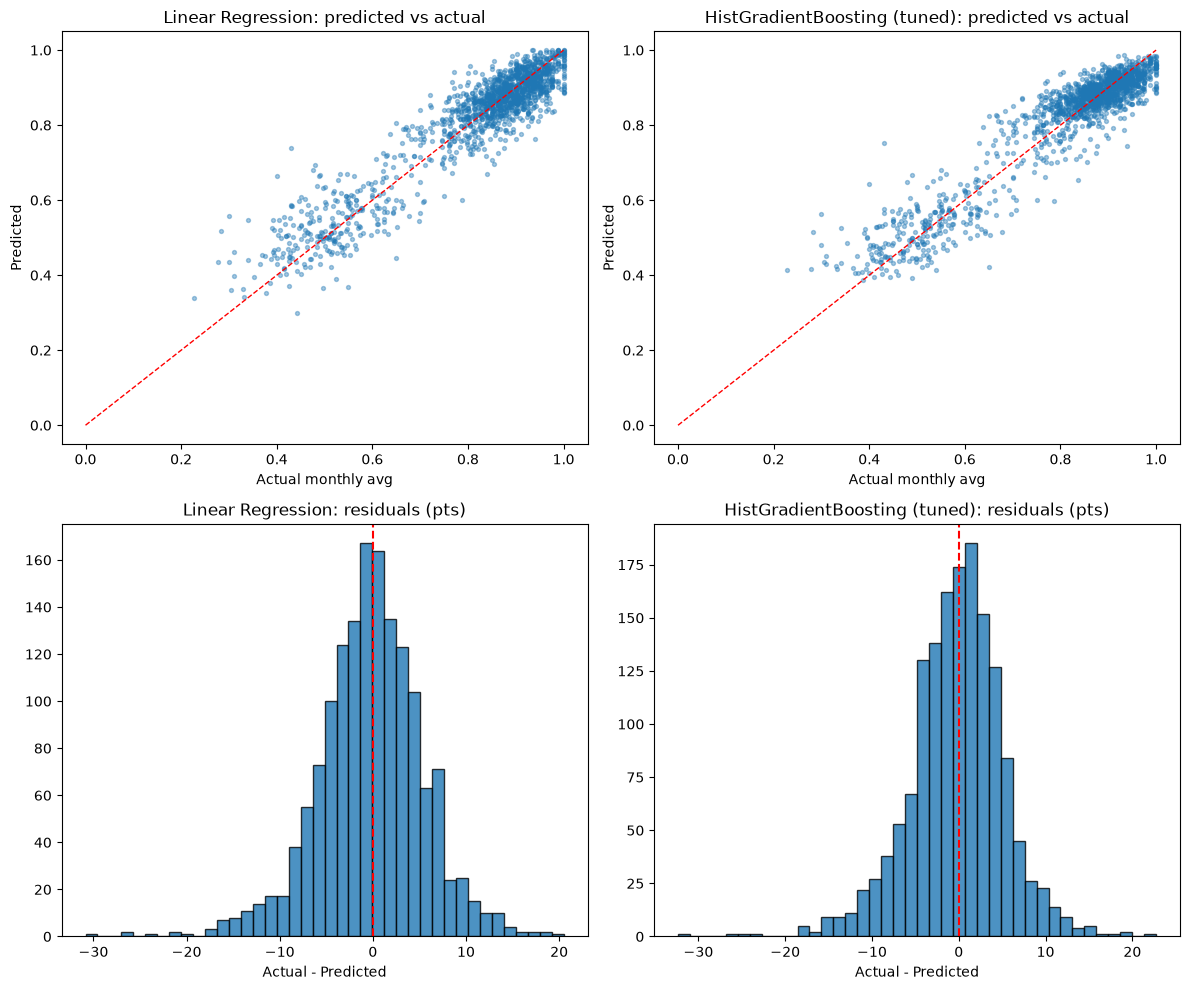

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, name in zip(axes[0], ['Linear Regression', 'HistGradientBoosting (tuned)']):
    ax.scatter(y_te, preds[name], s=8, alpha=0.4)
    ax.plot([0, 1], [0, 1], 'r--', lw=1)
    ax.set_title(f'{name}: predicted vs actual'); ax.set_xlabel('Actual monthly avg'); ax.set_ylabel('Predicted')
for ax, name in zip(axes[1], ['Linear Regression', 'HistGradientBoosting (tuned)']):
    ax.hist((y_te - preds[name]) * 100, bins=40, edgecolor='k', alpha=0.8)
    ax.axvline(0, color='r', ls='--'); ax.set_title(f'{name}: residuals (pts)'); ax.set_xlabel('Actual - Predicted')
plt.tight_layout(); plt.show()

أقوى 12 معامل في Linear Regression (أرقام متعمل لها scaling):


,coef
num__last_month_avg,0.0866
num__prev_all_avg,0.0314
num__prev2_month_avg,0.0132
cat__group_id_G04,-0.0125
cat__group_id_G10,0.0124
cat__group_id_G01,0.0122
cat__group_id_G35,0.0117
cat__group_id_G20,-0.0108
cat__group_id_G33,-0.0104
num__last_hw,0.0102


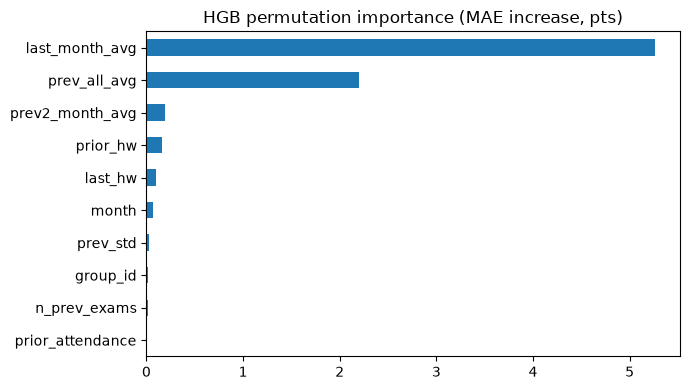

In [21]:
names = linear.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(linear.named_steps['model'].coef_, index=names).sort_values(key=abs, ascending=False)
print('أقوى 12 معامل في Linear Regression (أرقام متعمل لها scaling):')
display(coefs.head(12).round(4).to_frame('coef'))
assert coefs.abs().max() < 10, 'معامل ضخم = غالبًا عمود بايظ (تاريخ/ID/نص) دخل الـ features'

imp = permutation_importance(hgb_best, X_te, y_te, n_repeats=5, random_state=SEED,
                             scoring='neg_mean_absolute_error', n_jobs=-1)
imp_s = pd.Series(imp.importances_mean * 100, index=FEATURES).sort_values(ascending=False)
imp_s.head(10).sort_values().plot.barh(figsize=(7, 4), title='HGB permutation importance (MAE increase, pts)')
plt.tight_layout(); plt.show()

top = results.drop(columns='MAE gain vs best baseline (pts)')
if (top['R2'] > 0.95).any():
    print('تحذير: R2 فوق 0.95، راجع الـ features تاني، غالبًا فيه تسريب.')